# University Football: análise exploratória do rótulo

O alvo `Injury_Next_Season` tem proveniência e semântica clínica não resolvidas. Este notebook não valida previsão clínica. Veja o README para divergências entre artigo, metadados e CSV.

In [1]:
import json
import pandas as pd
from IPython.display import display, Markdown, Image
from pipeline import ROOT, FEATURES, TARGET, download, inspect, run
if not (ROOT / 'results/summary.json').exists():
    run()
source, metadata = download()
df = pd.read_csv(source)
summary = json.loads((ROOT / 'results/summary.json').read_text(encoding='utf-8'))
display(pd.Series(inspect(df), name='auditoria').to_frame())
display(df.head())

,auditoria
rows,800
columns,19
missing_cells,0
duplicates,0
positive_labels,400
prevalence,0.5
athlete_id_available,False
event_dates_available,False
bmi_max_recalculation_error,0.0
stress_values_above_article_PSS10_max40,715


,Age,Height_cm,Weight_kg,Position,Training_Hours_Per_Week,Matches_Played_Past_Season,Previous_Injury_Count,Knee_Strength_Score,Hamstring_Flexibility,Reaction_Time_ms,Balance_Test_Score,Sprint_Speed_10m_s,Agility_Score,Sleep_Hours_Per_Night,Stress_Level_Score,Nutrition_Quality_Score,Warmup_Routine_Adherence,Injury_Next_Season,BMI
0,22,173,64,Midfielder,11.575308,36,1,77.460279,79.115738,284.487853,91.212476,5.874630,77.599705,8.238293,46.616415,81.472206,1,0,21.383942
1,18,170,67,Midfielder,12.275869,37,2,72.634442,82.541688,250.579249,87.294078,5.796269,94.418987,8.983737,49.368037,81.056677,1,0,23.183391
2,22,186,75,Forward,12.254896,12,2,77.064490,75.943631,269.119918,83.440688,5.731209,70.179176,7.229193,43.132808,64.877457,0,1,21.678807
3,20,172,62,Defender,9.006678,11,1,82.810232,73.878324,226.376412,87.591894,6.220212,83.473824,7.681029,51.528529,89.824744,1,0,20.957274
4,18,172,94,Midfielder,12.683668,10,2,76.772859,76.653043,229.021042,83.125161,5.385958,87.037256,6.728091,52.379718,71.569197,0,1,31.773932


## Dicionário

Sem identificador de atleta nem datas. Não converter o escore de estresse em PSS-10 nem atribuir unidade ao sprint sem esclarecimento. 400 rótulos em cada classe não estimam incidência populacional.

In [2]:
display(pd.DataFrame(json.loads((ROOT / 'results/data_dictionary.json').read_text(encoding='utf-8'))))
print('Licença informada:', metadata.get('licenseName'))
print('Hash CSV:', summary['sha256_csv'])

,column,dtype,missing,unique,minimum,maximum
0,Age,int64,0,7,18.000000,24.000000
1,Height_cm,int64,0,42,154.000000,200.000000
2,Weight_kg,int64,0,53,45.000000,105.000000
3,Position,str,0,4,NaN,NaN
4,Training_Hours_Per_Week,float64,0,781,5.000000,18.866608
5,Matches_Played_Past_Season,int64,0,35,5.000000,39.000000
6,Previous_Injury_Count,int64,0,9,0.000000,8.000000
7,Knee_Strength_Score,float64,0,800,52.391351,93.900051
8,Hamstring_Flexibility,float64,0,800,58.180381,100.000000
9,Reaction_Time_ms,float64,0,800,180.000000,306.730851


Licença informada: CC0: Public Domain
Hash CSV: 73b692b2a4df5f544383929a09f4502663fe34a5a5e40aee9289e11f72840859


## Cruzamentos e avaliação OOF

Cinco folds externos por linha, calibração RF em três folds internos. A identidade de pessoa por linha é informada pelo publicador, não verificável no CSV. AUC, Brier e calibração referem-se somente ao rótulo fornecido.

In [3]:
display(Markdown((ROOT / 'results/RESULTADOS.md').read_text(encoding='utf-8')))
pred = pd.read_csv(ROOT / 'data/processed/oof_predictions.csv')
assert pred.row_id.is_unique and len(pred) == len(df)
assert pred['fold'].between(0,4).all()
assert pred[['prevalencia','logistica','rf_sigmoid']].notna().all().all()
display(pd.DataFrame(summary['sleep_stress_strata']))

# Resultados executados - University Football

**Classificação do rótulo publicado; não validação de lesão clínica.**

Linhas: 800; rótulo 1: 400; prevalência do rótulo: 50.00%.

| Modelo | ROC-AUC OOF | IC 95% condicional | AP | Brier | Log loss |
|---|---:|---|---:|---:|---:|
| prevalencia | 0.5000 | 0.500–0.500 | 0.5000 | 0.2500 | 0.6931 |
| logistica | 0.9900 | 0.985–0.994 | 0.9901 | 0.0389 | 0.1298 |
| rf_sigmoid | 0.9845 | 0.978–0.990 | 0.9843 | 0.0473 | 0.1634 |

## Correlações exploratórias

| Variável | Spearman |
|---|---:|
| Sleep_Hours_Per_Night | -0.516 |
| Balance_Test_Score | -0.499 |
| Sprint_Speed_10m_s | -0.476 |
| Knee_Strength_Score | -0.462 |
| Hamstring_Flexibility | -0.457 |
| Nutrition_Quality_Score | -0.422 |
| Agility_Score | -0.401 |
| Warmup_Routine_Adherence | -0.265 |
| Height_cm | -0.053 |
| Matches_Played_Past_Season | -0.045 |
| Weight_kg | +0.017 |
| Age | +0.021 |
| Training_Hours_Per_Week | +0.028 |
| BMI | +0.036 |
| Previous_Injury_Count | +0.381 |
| Reaction_Time_ms | +0.482 |
| Stress_Level_Score | +0.540 |


,sleep_group,stress_group,sum,count,mean
0,Sono baixo,Estresse baixo,23,57,0.403509
1,Sono baixo,Estresse médio,75,88,0.852273
2,Sono baixo,Estresse alto,114,122,0.934426
3,Sono médio,Estresse baixo,20,89,0.224719
4,Sono médio,Estresse médio,37,90,0.411111
5,Sono médio,Estresse alto,75,87,0.862069
6,Sono alto,Estresse baixo,9,121,0.074380
7,Sono alto,Estresse médio,20,88,0.227273
8,Sono alto,Estresse alto,27,58,0.465517


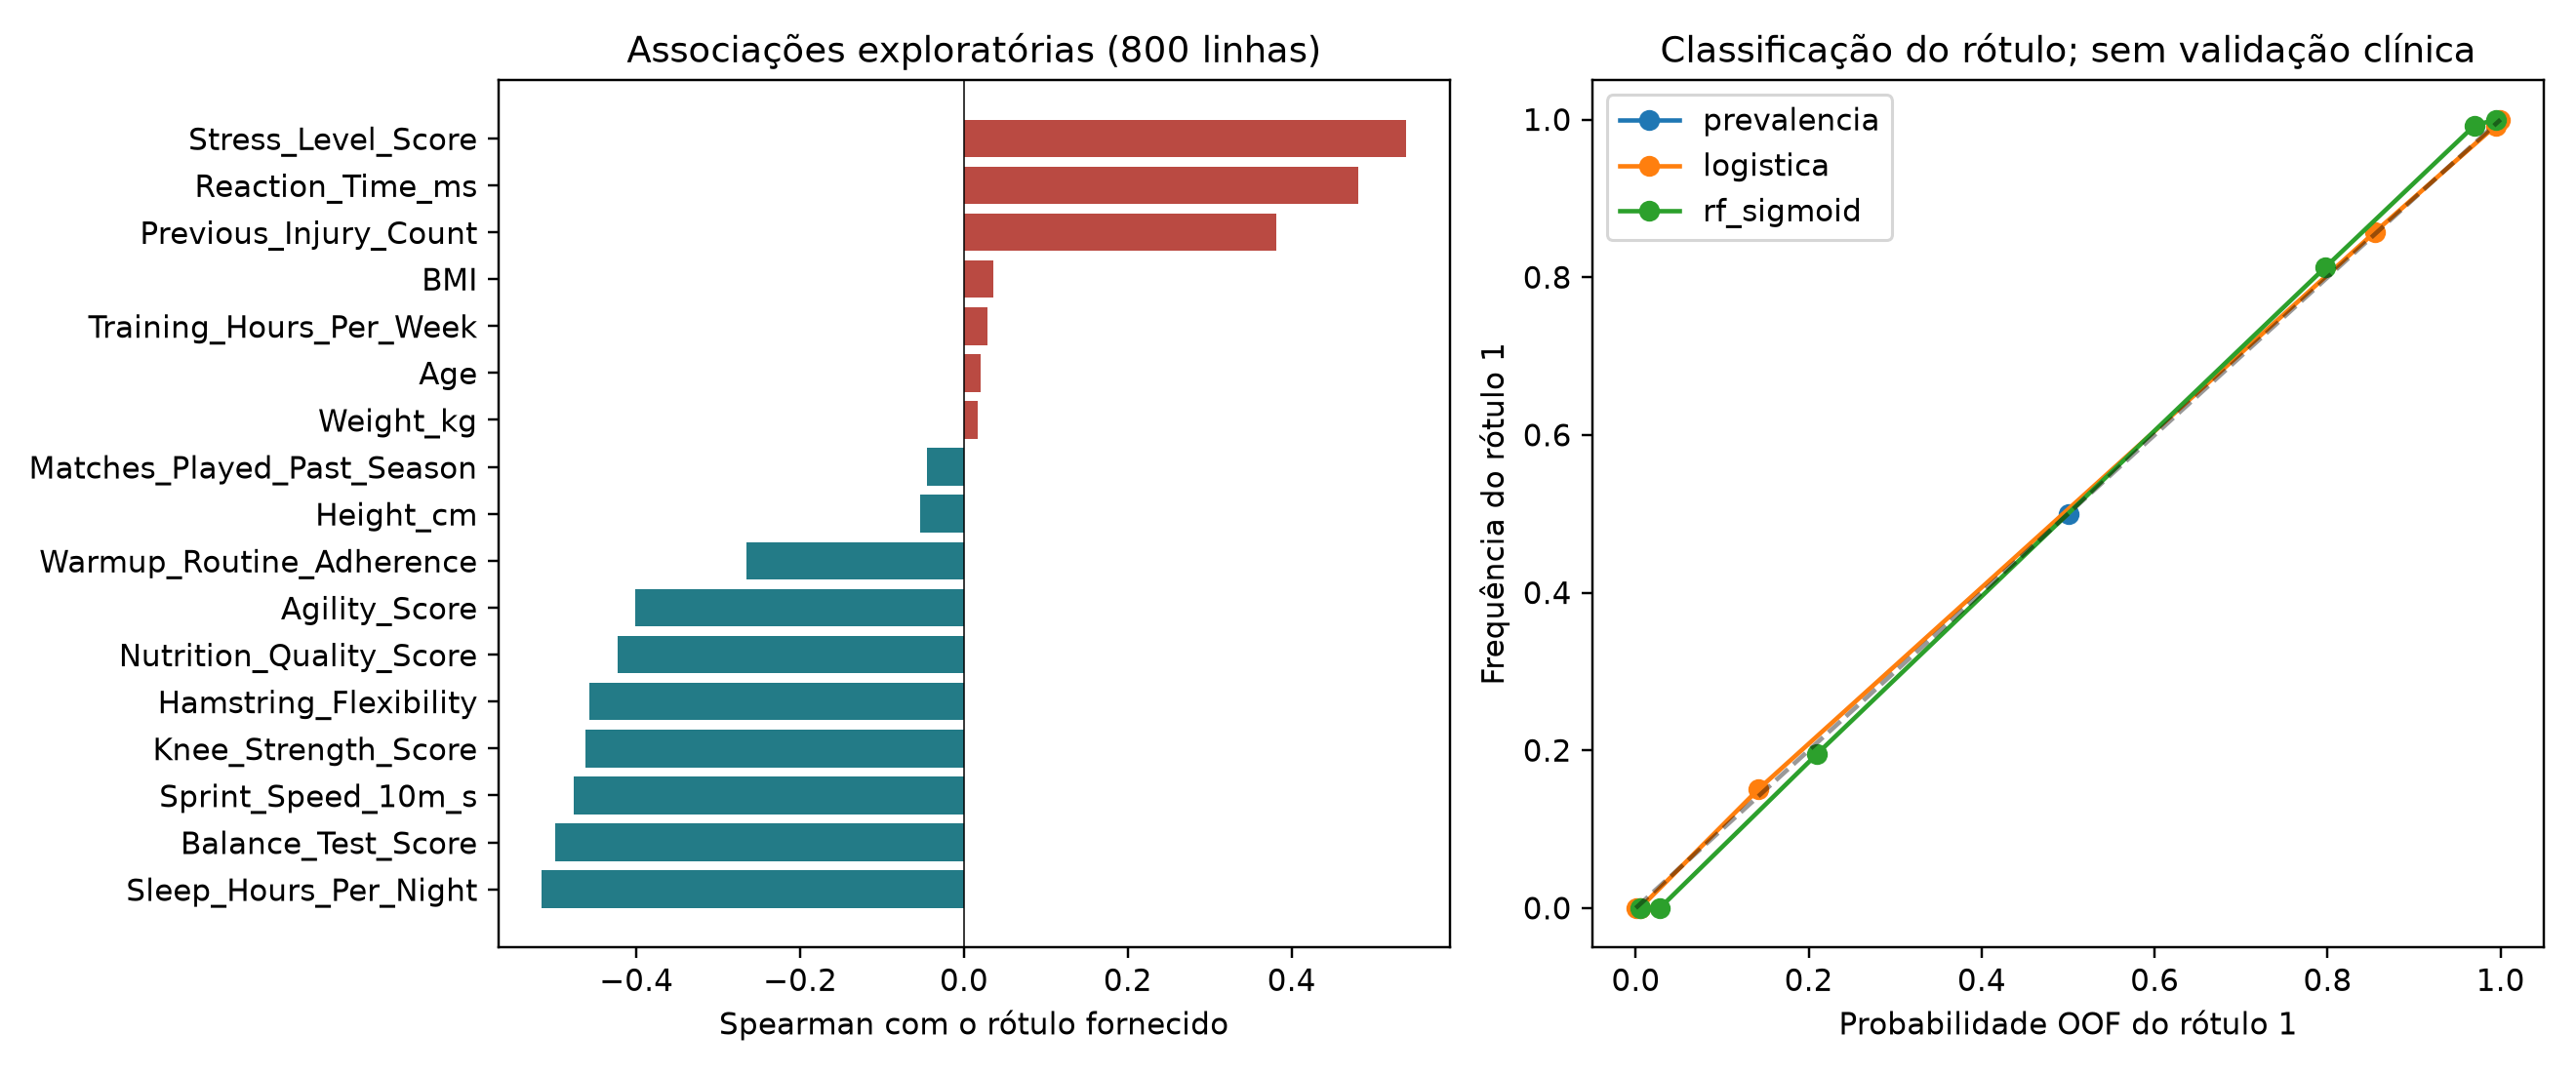

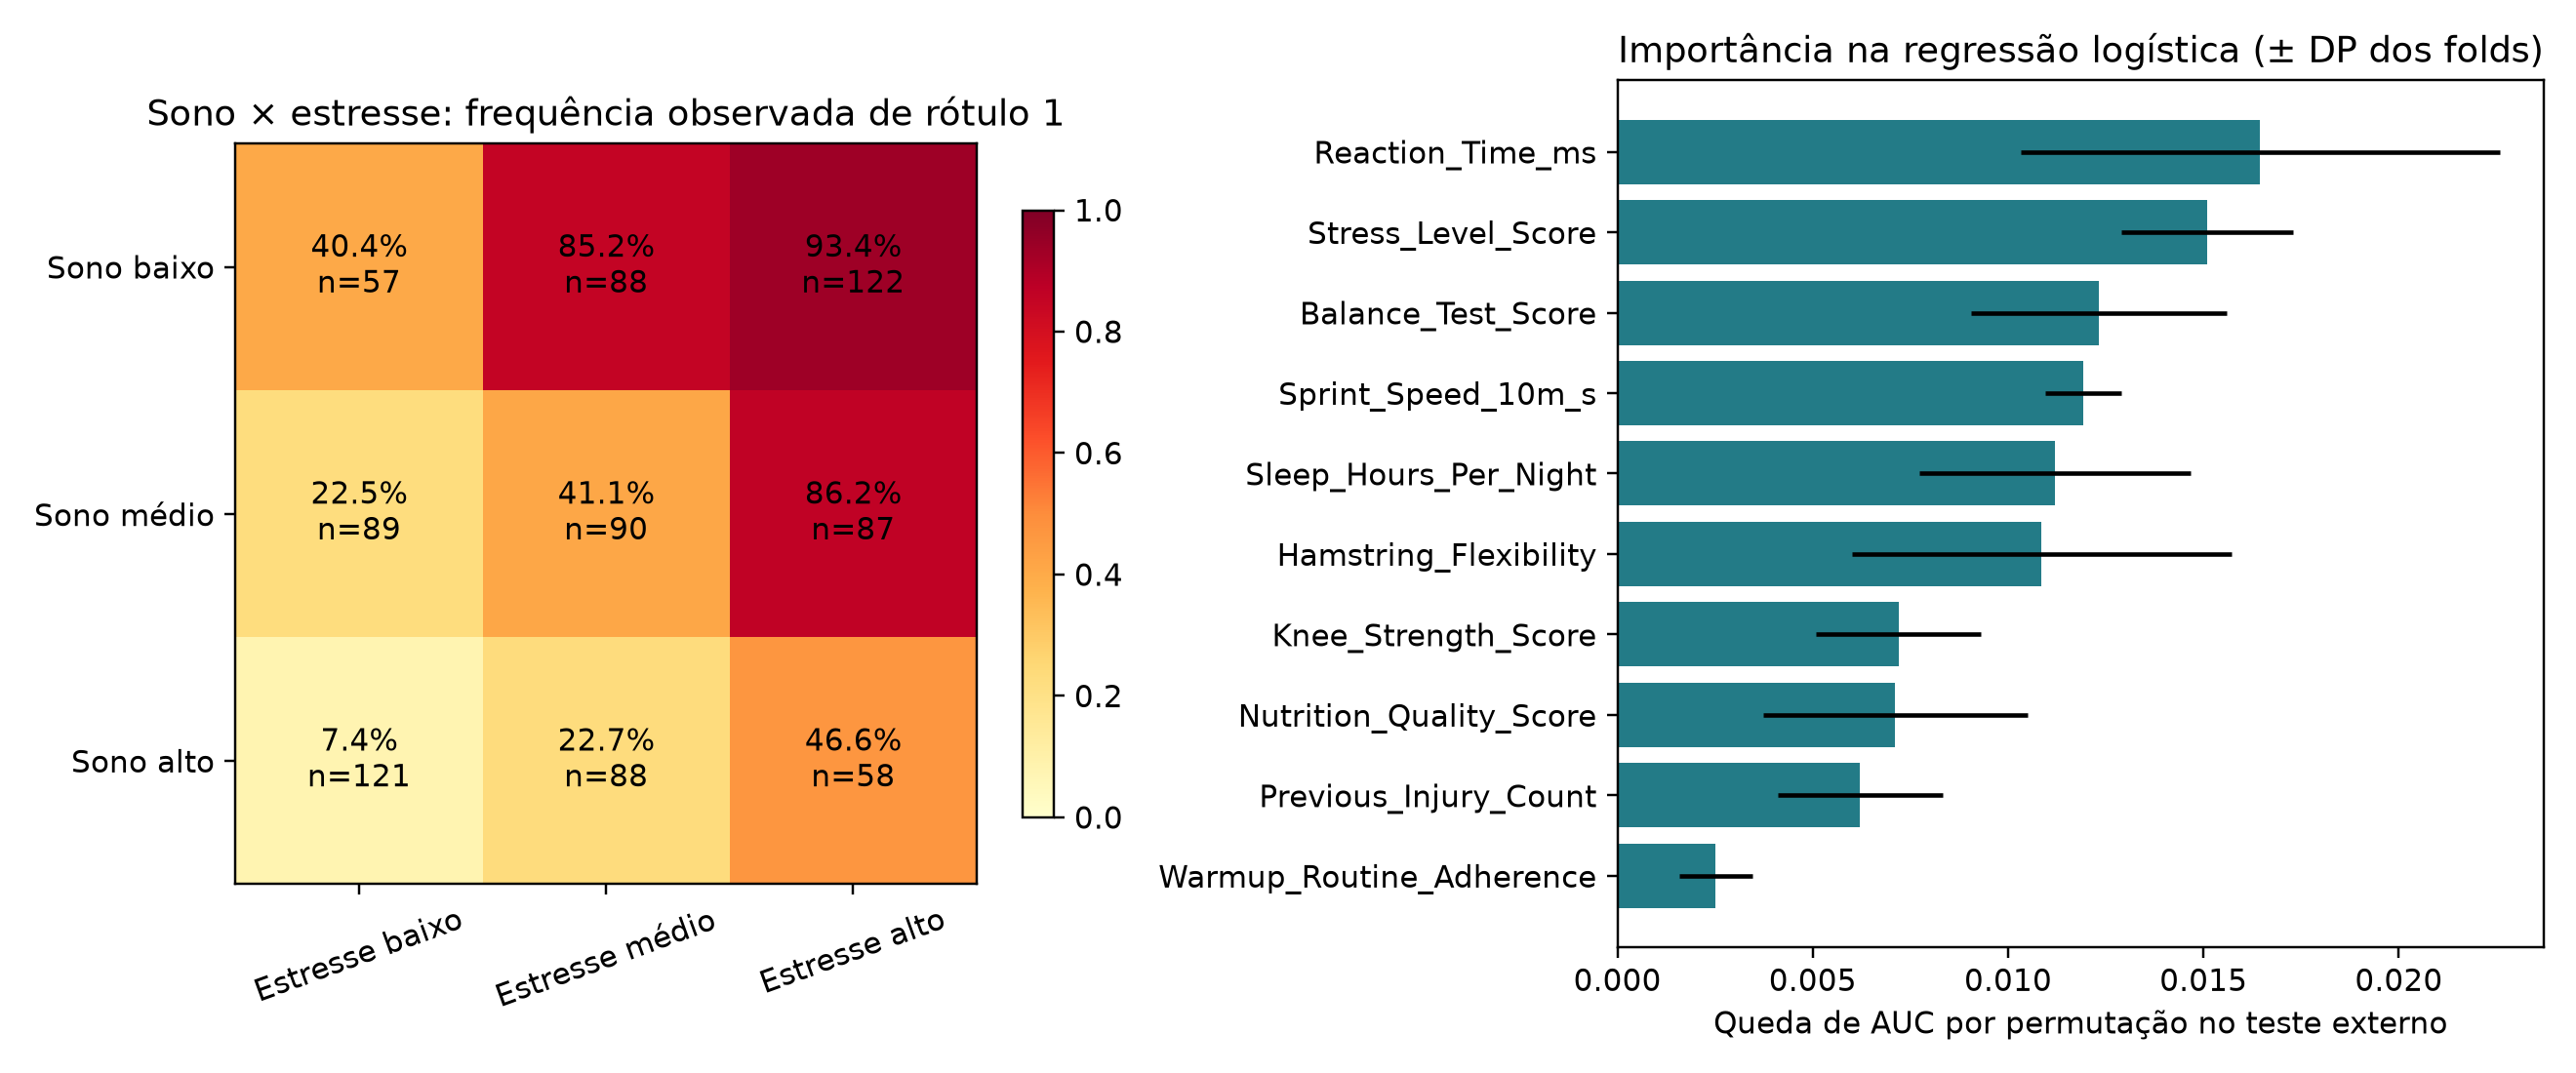

In [4]:
display(Image(filename=str(ROOT / 'figures/associacoes_e_calibracao.png')))
display(Image(filename=str(ROOT / 'figures/sono_estresse_e_importancia.png')))

## Limites e reprodução

Desfecho conflitante nas fontes; escala de estresse inconsistente; sprint com unidade a esclarecer; sem eventos datados ou diagnóstico de isquiotibiais. Nenhuma probabilidade clínica ou faixa de manejo é produzida. Para recalcular: `python university_football/pipeline.py` na raiz do Scout.